# GCEN on Mumbai PM10 — Step 1 of 2: tuning one horizon with Optuna

This notebook tunes the **Graph Convolutional Engression Network (GCEN)** from the `stengression` package (Pathak & Chakraborty, 2026, TMLR) for **one** forecast horizon, set by `HORIZON` at the top of Part 1. Run **three copies in parallel**, one per horizon (`"short"`, `"medium"`, `"long"`); each writes its own study file, so they never interfere. Then run **`gcen-final.ipynb`**, which merges the three studies and does the final training and test forecasts.

| Part | Contents |
|---|---|
| 0 | Installation, imports, versions |
| 1 | Configuration (**`HORIZON`**), search space |
| 2 | Data (GraphSVR Mumbai PM10, 17 stations, daily) |
| 3 | Spatial graph from station coordinates |
| 4 | Train / validation / test split + leakage checks |
| 6 | Shared helpers (model builder, package energy score check, sampling, metrics) |
| 7 | **Optuna tuning for `HORIZON`** on the validation window |
| 8 | Save the study and the best settings |

**No test data are used here.** Models are fitted on the training days and scored on the validation days only; the test window is not touched until the final notebook.

**Kaggle workflow**
1. Settings → **Accelerator: GPU** and **Internet: on** (the data are read from GitHub; or attach the GraphSVR csv files as a dataset under `/kaggle/input/graphsvr`).
2. Make three copies of this notebook (e.g. *gcen-tune-short*, *-medium*, *-long*) and set `HORIZON` in each.
3. Run each with **Save Version → Save & Run All (Commit)**, so they run in the background and their output folders are kept.
4. If a run stops at `MAX_HOURS` before 100 trials, attach its output to a new copy and set `PREVIOUS_DB` to its `optuna_<horizon>.db`: it continues where it stopped.
5. In the final notebook: **Add Input → Your Work → Notebooks** and add the three tuning notebooks.

## Part 0a — Installation

* `stengression` **0.0.3** is the authors' package (Pathak & Chakraborty, 2026). It only needs `torch`, `numpy`, `pandas`, `matplotlib`, `tqdm`; Kaggle already ships `torch`, so it is not reinstalled.
* `optuna` runs the hyper-parameter search; `statsforecast` provides the AutoETS / AutoARIMA benchmarks (final notebook).
* No Darts here: GCEN is a plain PyTorch model, trained with the package's own `fit` loop.

In [1]:
%%capture install_log
!pip install -q "stengression==0.0.3" optuna statsforecast

In [2]:
# Show only the tail of the install log (errors would appear here).
if "install_log" in globals():
    print(install_log.stdout[-1500:] or "install finished quietly")
    print(install_log.stderr[-1500:])
else:
    print("No install log in this kernel session (fine after a restart) - continue to Part 1.")

install finished quietly



## Part 0b — Imports and versions

Package versions are recorded here and saved at the end of the notebook. A GPU is strongly recommended: on a 2-core CPU the default GCEN (5 LSTM layers × 91 units) needs about 50 s per epoch.

In [3]:
import os, sys, json, time, platform, warnings, logging, glob, shutil
from importlib.metadata import version as pkg_version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, optuna
from torch.utils.data import DataLoader
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner, NopPruner
from optuna.trial import TrialState

import stengression
import stengression.Losses as st_losses
from stengression import GCEN, GraphInfo, GraphConv, SpatioTemporalDataset, compute_adjacency_matrix

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONS = {
    "python": platform.python_version(),
    "stengression": pkg_version("stengression"),
    "torch": torch.__version__,
    "optuna": optuna.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print(json.dumps(VERSIONS, indent=2))
assert VERSIONS["stengression"] == "0.0.3", "This notebook was written for stengression 0.0.3"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only - expect long run times")

{
  "python": "3.13.16",
  "stengression": "0.0.3",
  "torch": "2.11.0+cu130",
  "optuna": "5.1.0",
  "numpy": "2.1.3",
  "pandas": "2.3.3"
}
Device: cuda | Tesla T4


## Part 1 — Configuration

Everything you might change lives here. **Set `HORIZON` in the first line** (tuning notebook only); leave everything else identical across the three tuning runs and the final notebook. The final notebook checks this through `tuning_fingerprint`.

**Dataset.** `Mumbai_PM10` from the GraphSVR repository (Jahana et al.): daily PM10 (µg/m³) at 17 Mumbai monitoring stations, 1 Jan 2021 – 31 Dec 2024 (1,461 days). It was chosen over the other three GraphSVR datasets because it has the fewest abrupt jumps and the smoothest test windows (see the implementation-choices PDF). `DATASET = "Delhi_PM25"` switches to Delhi PM2.5 (37 stations, 2019–2023) with no other change.

**Fixed settings** (not tuned):

| Setting | Value | Source |
|---|---|---|
| Horizons H | 30 / 60 / 90 days | paper §6.2, daily datasets |
| Validation length V | 60 / 90 / 120 days | paper App. E.1, daily data |
| Lookback p | 60 days | authors' GCEN example (daily data); the paper does not report p |
| Adjacency | thresholded Gaussian kernel on Haversine distance, σ̃² = 0.9949, ε = 0.0769, self-loops | paper §4.1; σ̃², ε as in the authors' example |
| Graph (`GRAPH`) | **`"complete"`**: every station linked to every other (distance scale n = 10,000, GraphSVR's own setting) | best of four graphs on validation (Part 3); `"10km"` = the sparser alternative |
| Graph convolution | mean aggregation, concat combination, no activation | authors' example |
| Noise | additive, `noise_std` = 1 (package default) | paper §4.1, authors' example |
| Energy-score loss | `stengression.Losses.energy_score_loss` | package |
| M / epochs / batch / shuffle | 2 / 100 / 64 / no shuffling | paper §6.2, App. E.1; authors' example |
| Standardisation | per station, mean and sd of the training data | paper §6.2 |
| Prediction | 100 trajectories × 50 repeats, median point forecast, rounded | paper §6.2, package `evaluate_forecasts` |
| Final training seeds | 0–4 | EnBlockRNN protocol |

**Tuned settings** (`SEARCH_SPACE`, per horizon), exactly the paper's GCEN search space plus the noise distribution, which the paper also chose on validation:

| Hyper-parameter | Range | Source |
|---|---|---|
| `gcn_out_feat` | 1 – 10 (integer) | paper: output size of the spatial module |
| `lstm_hidden_dim` | 2 – 100 (integer) | paper |
| `lstm_num_layers` | 1 – 5 (integer) | paper |
| `lstm_dropout` | [0.0, 0.5] (only sampled with ≥ 2 layers; PyTorch applies it between layers only) | paper |
| `lr` | [1e-5, 0.1], log scale | paper (Adam) |
| `noise_dist` | Gaussian / uniform | paper §6.2: "selecting the noise distribution was based on a validation approach" |

**Trial 0** is the GCEN configuration published in the authors' example notebook for daily data (Belgium COVID-19, 30 days): `gcn_out_feat` 6, hidden 91, 5 layers, dropout 0.305, lr 0.00427, uniform noise. The tuned model can therefore only match or beat it on validation.

**Tuning budget:** `N_TRIALS` = 100 per horizon (paper), each scored as the mean over `TUNE_SEEDS` = 3 training seeds (EnBlockRNN protocol).

In [4]:
HORIZON = "short"    # <-- tuning notebook: the ONE horizon this run tunes: "short" (H=30) | "medium" (H=60) | "long" (H=90)
RUN_MODE = "full"    # "full" | "quick" (smoke test: 2 epochs, 3 trials x 1 seed)

CFG = dict(
# data
    DATASET="Mumbai_PM10",
    DATASETS={
        "Mumbai_PM10": dict(data="Mumbai_PM10_Data.csv", stations="Mumbai_Stations_PM10.csv", start="2021-01-01"),
        "Delhi_PM25":  dict(data="Delhi_PM25_Data.csv",  stations="Delhi_Stations_PM25.csv",  start="2019-01-01"),
    },
    DATA_URL="https://raw.githubusercontent.com/ctanujit/GraphSVR/main/Data/",
    LOCAL_DIR="/kaggle/input/graphsvr",     # used instead if the GraphSVR csv files are attached as a Kaggle dataset
    UNITS="PM10 (µg/m³)",
    HORIZONS={"short": {"H": 30, "V": 60}, "medium": {"H": 60, "V": 90}, "long": {"H": 90, "V": 120}},
    LOOKBACK=60,            # p_lag
# graph (paper Sec. 4.1; sigma2 and epsilon from the authors' example notebook)
    SIGMA2=0.9948808074595779,
    EPSILON=0.07692416606625796,
    GRAPH="complete",       # "complete": every station linked (GraphSVR's setting; best on validation) | "10km": neighbours within ~10 km
    GRAPH_SCALES={"complete": 10_000.0, "10km": 6.25},   # `n` in compute_adjacency_matrix (km): distances are divided by this
    SELF_LOOPS=True,        # authors' example: np.fill_diagonal(adjacency, 1)
    GRAPH_CONV=dict(aggregation_type="mean", combination_type="concat", activation=None),
# engression
    M_TRAIN=2,              # M: noisy forward passes per batch in the energy score
    NOISE_ENCODE="add",
    NOISE_STD=1.0,          # package default
    ES_LOSS="package",      # stengression.Losses.energy_score_loss, asserted before every fit
# optimisation (paper App. E.1 + authors' example)
    N_EPOCHS=100,
    BATCH_SIZE=64,
    SHUFFLE=False,
    GCN_SEED_BASE=21,       # training seed s uses gcn_seed = 21 + s and temporal_seed = 9 + s (s = 0: the authors' seeds)
    TEMPORAL_SEED_BASE=9,
# tuning (Optuna)
    N_TRIALS=100,           # trials per horizon (completed + pruned)
    TUNE_SEEDS=[0, 1, 2],   # training seeds averaged inside every trial
    TUNE_N_PRED_SAMPLES=100,# trajectories per validation forecast
    PRUNE=True,             # stop a trial after seed 1 or 2 if it is clearly worse than the median trial so far
    OPTUNA_SEED=42,         # TPE sampler seed (reproducible search)
    MAX_HOURS=11.0,         # stop starting new trials after this long, so a Kaggle session (12 h) can still save
# prediction / evaluation (paper Sec. 6.2)
    N_PRED_SAMPLES=100,
    N_EVAL_REPEATS=50,
    SEEDS=[0, 1, 2, 3, 4],
    ALPHA=0.05,
    ROUND_FORECASTS=True,   # the package's evaluate_forecasts rounds every sample before scoring
    RUN_BENCHMARKS=True,
    SEASON=7,               # weekly cycle in daily air-quality data (seasonal naive, AutoETS, AutoARIMA)
    OUT_DIR=f"gcen_tuning_{HORIZON}",
    PREVIOUS_DB=None,       # optional: path to an earlier optuna_<horizon>.db to resume from (e.g. after the 12 h limit)
)
assert HORIZON in CFG["HORIZONS"], HORIZON
CFG["DIST_SCALE_KM"] = CFG["GRAPH_SCALES"][CFG["GRAPH"]]

# Trial 0: the GCEN settings in the authors' example notebook (stengression/examples, Belgium COVID-19, daily, 30 days)
DEFAULT_PARAMS = dict(gcn_out_feat=6, lstm_hidden_dim=91, lstm_num_layers=5, lstm_dropout=0.30479293048737066,
                      lr=0.00426979947571805, noise_dist="uniform")

SEARCH_SPACE = dict(                     # paper App. E.1 (GCEN)
    gcn_out_feat=(1, 10),                # int
    lstm_hidden_dim=(2, 100),            # int
    lstm_num_layers=(1, 5),              # int
    lstm_dropout=(0.0, 0.5),             # float, only if lstm_num_layers > 1
    lr=(1e-5, 1e-1),                     # float, log scale
    noise_dist=["gaussian", "uniform"],  # categorical (paper: chosen on validation)
)

if RUN_MODE == "quick":
    CFG.update(N_EPOCHS=2, N_TRIALS=3, TUNE_SEEDS=[0], N_EVAL_REPEATS=3, SEEDS=[0, 1], OUT_DIR=f"gcen_tuning_{HORIZON}_quick")

def tuning_fingerprint(hname):
    # Everything that must be identical between the tuning runs and the final notebook (stored with each study)
    keys = ["DATASET", "LOOKBACK", "GRAPH", "SIGMA2", "EPSILON", "DIST_SCALE_KM", "SELF_LOOPS", "GRAPH_CONV", "M_TRAIN",
            "NOISE_ENCODE", "NOISE_STD", "ES_LOSS", "N_EPOCHS", "BATCH_SIZE", "SHUFFLE", "GCN_SEED_BASE",
            "TEMPORAL_SEED_BASE", "TUNE_SEEDS", "TUNE_N_PRED_SAMPLES", "PRUNE", "OPTUNA_SEED", "ALPHA", "ROUND_FORECASTS"]
    fp = dict(run_mode=RUN_MODE, horizon=hname, **CFG["HORIZONS"][hname], **{k: CFG[k] for k in keys},
              default_params=DEFAULT_PARAMS, search_space=SEARCH_SPACE)
    return json.loads(json.dumps(fp))            # tuples -> lists, as Optuna stores them

## Part 2 — Loading the data

The GraphSVR files have one column per station (`V4`, `V5`, …, numbered as in the original station list) and one row per day, with no dates; the station file lists the stations in the same order, with latitude and longitude. The README gives the period (Mumbai: 2021–2024), so we attach a daily date index. Gaps in the raw records were already filled by the data providers (straight-line stretches are visible in the plot).

In [5]:
spec = CFG["DATASETS"][CFG["DATASET"]]
def read_graphsvr(fname):
    local = os.path.join(CFG["LOCAL_DIR"], fname)
    return pd.read_csv(local if os.path.exists(local) else CFG["DATA_URL"] + fname)

raw = read_graphsvr(spec["data"])
stations = read_graphsvr(spec["stations"]).dropna(subset=["Station"]).iloc[:, :3].reset_index(drop=True)
raw.index = pd.date_range(spec["start"], periods=len(raw), freq="D")
checks = {
    "one station row per data column": len(stations) == raw.shape[1],
    "no missing values": raw.isna().sum().sum() == 0,
    "non-negative values": (raw.values >= 0).all(),
    "station coordinates present": stations[["LAT", "LONG"]].notna().all().all(),
    "period ends on 31 Dec": raw.index[-1].strftime("%m-%d") == "12-31",
}
for k, v in checks.items():
    print(("OK  " if v else "FAIL"), k)
assert all(checks.values())
STATION_NAMES = stations["Station"].tolist()
Y = raw.values.astype(np.float32)                 # (T, N): days x stations, original units
DATES = raw.index
T_ALL, N = Y.shape
print(f"{CFG['DATASET']}: {T_ALL} days ({DATES[0].date()} - {DATES[-1].date()}), {N} stations")
raw.describe().T.round(1).head(N)

OK   one station row per data column
OK   no missing values
OK   non-negative values
OK   station coordinates present
OK   period ends on 31 Dec
Mumbai_PM10: 1461 days (2021-01-01 - 2024-12-31), 17 stations


,count,mean,std,min,25%,50%,75%,max
V4,1461.0,107.8,60.8,8.5,54.8,99.3,149.4,466.5
V5,1461.0,74.4,44.3,6.5,38.3,68.7,99.5,627.9
V7,1461.0,109.7,79.8,5.9,53.5,82.1,152.9,516.2
V9,1461.0,121.6,72.0,21.4,62.0,104.6,171.1,642.1
V10,1461.0,87.3,53.8,9.2,46.2,73.1,122.6,543.8
V11,1461.0,119.2,80.1,5.8,46.6,102.7,180.6,482.9
V13,1461.0,117.9,62.6,16.3,64.6,112.7,164.5,375.1
V16,1461.0,79.5,52.5,1.9,36.5,70.7,113.0,470.9
V17,1461.0,139.9,89.7,5.0,77.8,120.6,187.1,827.5
V18,1461.0,113.5,60.2,8.8,60.9,116.5,150.3,514.1


## Part 3 — The spatial graph (adjacency matrix)

Following §4.1 of the paper and the authors' example code:

1. Haversine distance d_ij (km) between every pair of stations.
2. Thresholded Gaussian kernel, `compute_adjacency_matrix(d, sigma2, epsilon, n)`: i and j are neighbours if exp(−(d_ij/n)² / σ̃²) ≥ ε, i.e. if d_ij ≤ n·√(−σ̃² ln ε) (the "interaction radius").
3. Self-loops on the diagonal, so each station's own value enters the neighbourhood mean.
4. `GraphInfo(edges=(i, j))` from the non-zero entries.

**Note.** The package's `GraphConv` uses only *which* edges exist (it averages neighbours with equal weight), not the kernel weights. So σ̃², ε and n act together through one number, the interaction radius. We keep σ̃² and ε from the authors' example; `GRAPH` sets n.

**Which graph (`GRAPH = "complete"`).** The paper gives no radius for new data, so before tuning we compared four graphs on the **validation** data only (H = 30, small untuned GCEN, 3 seeds, 31 rolling origins):

| Graph | Median neighbours | Validation CRPS (mean of 3 seeds) |
|---|---|---|
| 5 km | 1 (one station isolated) | 34.4 |
| 10 km (as sparse as the authors' example) | 5 | 32.1 |
| 20 km | 12 | 32.8 |
| **complete** (every station linked) | 16 | **29.0** |

The complete graph was best for all three seeds. This fits the data: Mumbai's stations are not more alike when they are closer (correlation hardly falls with distance), so the city-wide average is the most useful neighbour signal. It is also the graph GraphSVR effectively used on these data (n = 10,000). With mean aggregation, each station's GCN input is then its own value plus the average over all stations. `GRAPH = "10km"` switches to the local graph. Station order (row k of the station file = column k of the data) was confirmed by M. Panja.

GRAPH = 'complete' | all stations connected | edges (incl. self-loops) 289 | density 1.00 | neighbours per station: min 16, median 16, max 16


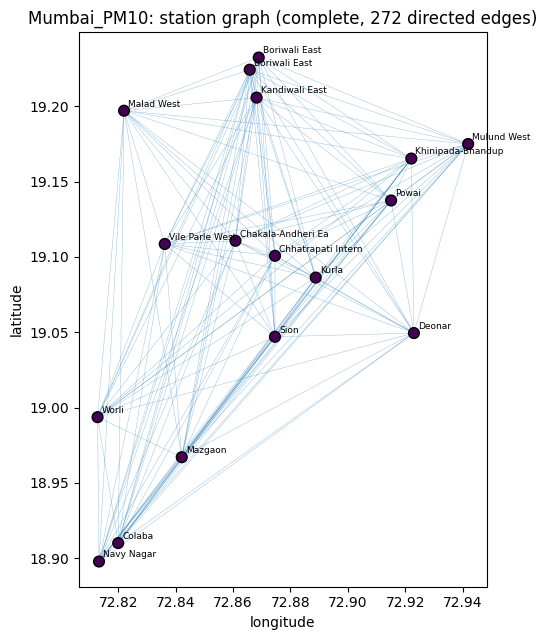

In [6]:
def haversine_km(lat, lon, R=6371.0):
    lat, lon = np.radians(np.asarray(lat, float)), np.radians(np.asarray(lon, float))
    a = (np.sin((lat[:, None] - lat[None]) / 2) ** 2
         + np.cos(lat[:, None]) * np.cos(lat[None]) * np.sin((lon[:, None] - lon[None]) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

DIST_KM = haversine_km(stations["LAT"], stations["LONG"])
ADJ = compute_adjacency_matrix(DIST_KM, sigma2=CFG["SIGMA2"], epsilon=CFG["EPSILON"], n=CFG["DIST_SCALE_KM"])
if CFG["SELF_LOOPS"]:
    np.fill_diagonal(ADJ, 1)
src, dst = np.where(ADJ == 1)
GRAPH = GraphInfo(edges=(src.tolist(), dst.tolist()), num_nodes=N)

RADIUS_KM = CFG["DIST_SCALE_KM"] * np.sqrt(-CFG["SIGMA2"] * np.log(CFG["EPSILON"]))
off = ADJ.copy(); np.fill_diagonal(off, 0)
deg = off.sum(1).astype(int)
radius_txt = "all stations connected" if off.sum() == N * (N - 1) else f"interaction radius {RADIUS_KM:.1f} km"
print(f"GRAPH = {CFG['GRAPH']!r} | {radius_txt} | edges (incl. self-loops) {len(src)} | "
      f"density {off.sum() / (N * (N - 1)):.2f} | neighbours per station: min {deg.min()}, median {np.median(deg):.0f}, max {deg.max()}")
assert deg.min() >= 1, "a station has no neighbours; increase DIST_SCALE_KM"

fig, ax = plt.subplots(figsize=(5.5, 6.5))
for i, j in zip(*np.where(np.triu(off) == 1)):
    ax.plot(stations.LONG[[i, j]], stations.LAT[[i, j]], color="tab:blue", lw=0.8 if off.mean() < 0.5 else 0.3, alpha=0.5)
ax.scatter(stations.LONG, stations.LAT, c=deg, cmap="viridis", s=60, zorder=3, edgecolor="k")
for i, nm in enumerate(STATION_NAMES):
    ax.annotate(nm.split(",")[0][:18], (stations.LONG[i], stations.LAT[i]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_title(f"{CFG['DATASET']}: station graph ({CFG['GRAPH']}, {len(src) - N} directed edges)"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.tight_layout(); plt.show()

## Part 4 — Train, validation, test split

Paper App. E.1, daily data. For each horizon:

1. **Test** = the last **H** days (H = 30 / 60 / 90).
2. **Validation** = the **V** days just before the test window (V = 60 / 90 / 120). Used **only** to score Optuna trials.
3. **Train** = everything before that.
4. **Tuning:** standardisation (per-station mean and sd) is fitted on **train**; each trial's model is trained on **train** and forecasts every rolling origin inside the validation window (V − H + 1 = 31 origins for every horizon). Validation days serve as *inputs* for later origins but are never trained on.
5. **Final model:** retrain on **train + validation** with the best settings (standardisation refitted on train + validation), and forecast the test window **once**, from the last 60 days before it.

Each horizon is a separate experiment with its own study and models.

,H (test days),V (validation days),train days,train period,validation period,test period,training windows (tuning),training windows (final),validation origins
short,30,60,1371,2021-01-01 → 2024-10-02,2024-10-03 → 2024-12-01,2024-12-02 → 2024-12-31,1282,1342,31
medium,60,90,1311,2021-01-01 → 2024-08-03,2024-08-04 → 2024-11-01,2024-11-02 → 2024-12-31,1192,1282,31
long,90,120,1251,2021-01-01 → 2024-06-04,2024-06-05 → 2024-10-02,2024-10-03 → 2024-12-31,1102,1222,31


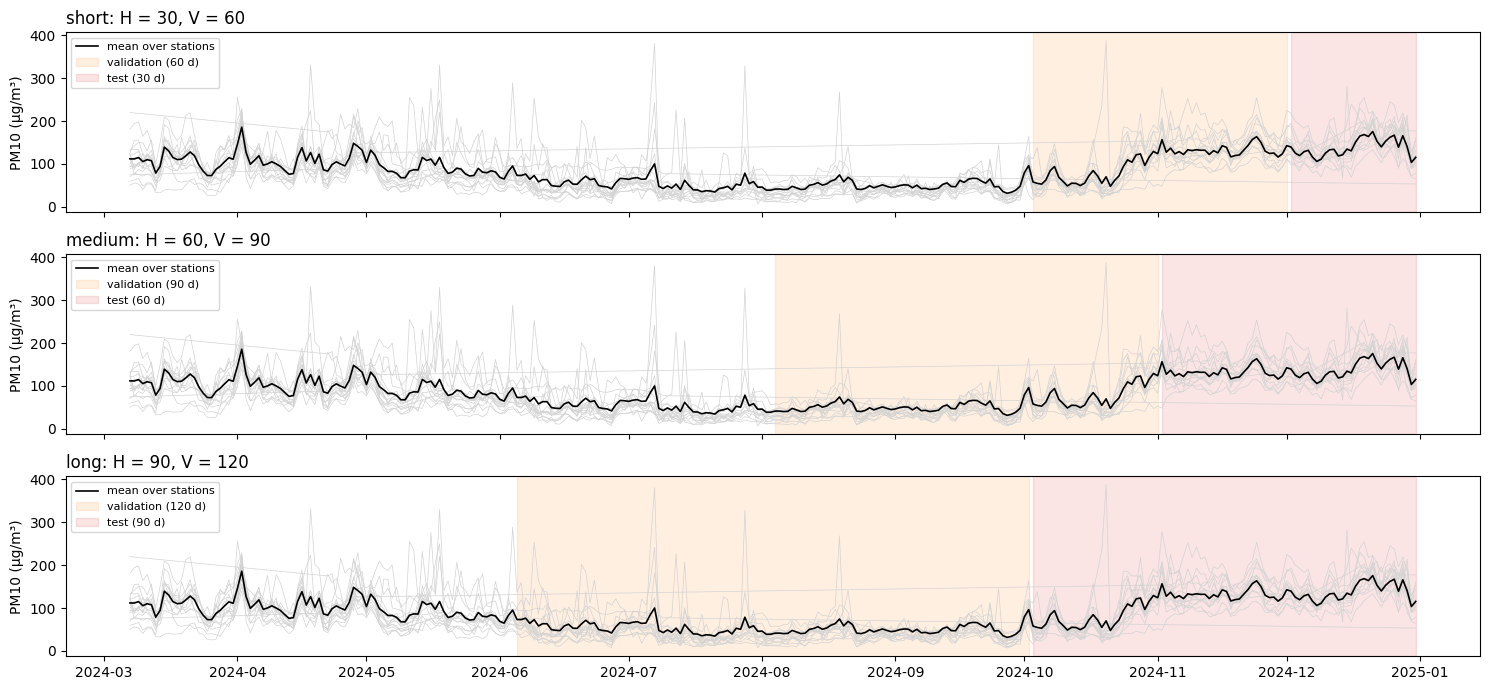

In [7]:
P = CFG["LOOKBACK"]
SPLITS = {}
for hname, hv in CFG["HORIZONS"].items():
    H, V = hv["H"], hv["V"]
    n_train = T_ALL - H - V
    sp = dict(H=H, V=V, n_train=n_train,
              train=Y[:n_train], val=Y[n_train:n_train + V], train_val=Y[:n_train + V], test=Y[-H:],
              dates_train=DATES[:n_train], dates_val=DATES[n_train:n_train + V], dates_test=DATES[-H:])
    sp["n_train_windows"] = n_train - P - H + 1
    sp["n_final_windows"] = n_train + V - P - H + 1
    sp["n_val_origins"] = V - H + 1
    SPLITS[hname] = sp

split_table = pd.DataFrame({h: {
    "H (test days)": s["H"], "V (validation days)": s["V"], "train days": s["n_train"],
    "train period": f"{s['dates_train'][0].date()} → {s['dates_train'][-1].date()}",
    "validation period": f"{s['dates_val'][0].date()} → {s['dates_val'][-1].date()}",
    "test period": f"{s['dates_test'][0].date()} → {s['dates_test'][-1].date()}",
    "training windows (tuning)": s["n_train_windows"], "training windows (final)": s["n_final_windows"],
    "validation origins": s["n_val_origins"]} for h, s in SPLITS.items()}).T
display(split_table)

fig, axes = plt.subplots(3, 1, figsize=(15, 7), sharex=True)
cut = 300
city = Y.mean(1)
for ax, (hname, s) in zip(axes, SPLITS.items()):
    ax.plot(DATES[-cut:], Y[-cut:], color="lightgray", lw=0.5)
    ax.plot(DATES[-cut:], city[-cut:], color="k", lw=1.2, label="mean over stations")
    ax.axvspan(s["dates_val"][0], s["dates_val"][-1], color="tab:orange", alpha=0.12, label=f"validation ({s['V']} d)")
    ax.axvspan(s["dates_test"][0], s["dates_test"][-1], color="tab:red", alpha=0.12, label=f"test ({s['H']} d)")
    ax.set_title(f"{hname}: H = {s['H']}, V = {s['V']}", loc="left"); ax.legend(loc="upper left", fontsize=8)
    ax.set_ylabel(CFG["UNITS"])
plt.tight_layout(); plt.show()

In [8]:
# Leakage checks: the test window is disjoint from, and strictly after, everything used for fitting or tuning
for hname, sp in SPLITS.items():
    test_start = T_ALL - sp["H"]
    assert sp["n_train"] + sp["V"] == test_start, hname
    assert len(sp["train_val"]) == test_start and len(sp["test"]) == sp["H"], hname
    assert sp["dates_train"][-1] < sp["dates_val"][0] <= sp["dates_val"][-1] < sp["dates_test"][0], hname
    assert np.array_equal(sp["test"], Y[test_start:]) and sp["n_val_origins"] >= 1, hname
    assert sp["n_train_windows"] > 0, hname
print("OK  train < validation < test for every horizon; train_val ends the day before the test window")

OK  train < validation < test for every horizon; train_val ends the day before the test window


## Part 6 — Shared helpers

* `Standardiser`: per-station mean and sd (sd with n − 1, as `torch.std` in the authors' example), fitted on the training part only.
* `build_gcen`: the package's `GCEN` with the graph, the fixed settings of Part 1 and a parameter dict. Training seed s sets `gcn_seed = 21 + s` and `temporal_seed = 9 + s`, so seed 0 reproduces the authors' initialisation.
* `fit_gcen`: the package's own `GCEN.fit` (Adam, M = 2 forward passes per batch). It **asserts that the loss is `stengression.Losses.energy_score_loss`**, records the per-epoch loss and stops on a non-finite loss.
* `sample_ensembles`: S trajectories for many forecast origins in one batched pass, in original units (rounded, as the package does). It is the same computation as the package's `predict`, which runs the S passes one at a time; the final notebook checks this.
* `paper_metrics`: the metrics of the package's `evaluate_forecasts` (SMAPE, MAE, RMSE, MASE, RMSSE, pinball 80/95, ρ-risk 0.5/0.9, CRPS, 95% coverage, Winkler), computed exactly as there, plus the mean 95% interval width. Pooled over all stations and days, like the package.

In [9]:
class Standardiser:
    # Per-station standardisation (paper Sec. 6.2): fit on the training part only
    def fit(self, arr):
        self.mean = arr.mean(0).astype(np.float32); self.std = arr.std(0, ddof=1).astype(np.float32)
        return self
    def transform(self, arr):
        return ((arr - self.mean) / self.std).astype(np.float32)
    def inverse(self, arr):
        return arr * self.std + self.mean
    def torch_params(self):                       # [mean, std] in the shape GCEN.predict(unstandardize=...) expects
        return [torch.tensor(self.mean)[:, None], torch.tensor(self.std)[:, None]]

def to_tensor(arr2d):
    return torch.tensor(arr2d, dtype=torch.float32).unsqueeze(-1)      # (T, N) -> (T, N, 1)

def build_gcen(H, params, seed, noise_std=None):
    layers = int(params["lstm_num_layers"])
    return GCEN(in_feat_dim=1, gcn_out_feat=int(params["gcn_out_feat"]), lstm_hidden_dim=int(params["lstm_hidden_dim"]),
                lstm_num_layers=layers, lstm_dropout=float(params.get("lstm_dropout", 0.0)) if layers > 1 else 0.0,
                p_lag=P, t_pred=H, graph_info=GRAPH, noise_encode=CFG["NOISE_ENCODE"], noise_dist=params["noise_dist"],
                noise_std=CFG["NOISE_STD"] if noise_std is None else noise_std, graph_conv_params=dict(CFG["GRAPH_CONV"]),
                gcn_seed=CFG["GCN_SEED_BASE"] + seed, temporal_seed=CFG["TEMPORAL_SEED_BASE"] + seed).to(DEVICE)

_PACKAGE_ES = st_losses.energy_score_loss            # the authors' estimator
assert CFG["ES_LOSS"] == "package"

class LossRecorder:
    # Passes every batch through `loss_fn` unchanged and keeps the values (GCEN.fit only plots them)
    def __init__(self, loss_fn): self.loss_fn, self.values = loss_fn, []
    def __call__(self, y_true, y_pred_samples):
        loss = self.loss_fn(y_true, y_pred_samples)
        v = loss.item()
        if not np.isfinite(v):
            raise RuntimeError("non-finite training loss (diverged)")
        self.values.append(v)
        return loss

def fit_gcen(model, train_sc, H, lr, seed, loss_fn=None, m_samples=None, n_epochs=None):
    # Train with the package's GCEN.fit; returns the per-epoch mean loss
    loss_fn = _PACKAGE_ES if loss_fn is None else loss_fn
    assert loss_fn is not _PACKAGE_ES or st_losses.energy_score_loss is _PACKAGE_ES
    n_epochs = n_epochs or CFG["N_EPOCHS"]
    ds = SpatioTemporalDataset(to_tensor(train_sc), input_seq_len=P, output_seq_len=H, multi_horizon=True)
    dl = DataLoader(ds, batch_size=CFG["BATCH_SIZE"], shuffle=CFG["SHUFFLE"])
    opt = torch.optim.Adam(model.parameters(), lr=float(lr))
    torch.manual_seed(1000 + seed)            # noise draws during training (GCEN.__init__ reseeds the global RNG)
    rec = LossRecorder(loss_fn)
    model.fit(data_loader=dl, optimizer=opt, loss_fn=rec, num_epochs=n_epochs, m_samples=m_samples or CFG["M_TRAIN"],
              device=DEVICE, monitor=False, visualize=False, verbose=False)
    return np.asarray(rec.values).reshape(n_epochs, len(dl)).mean(1)

@torch.no_grad()
def sample_ensembles(model, histories_sc, S, scaler, seed, chunk=256):
    # histories_sc: (K, p, N) standardised inputs. Returns (K, S, H, N) samples in original units.
    model.eval(); torch.manual_seed(seed)
    K = histories_sc.shape[0]
    X = torch.tensor(histories_sc, dtype=torch.float32, device=DEVICE).unsqueeze(-1).repeat_interleave(S, dim=0)
    out = torch.cat([model(X[i:i + chunk]) for i in range(0, len(X), chunk)])[..., 0]   # (K*S, H, N)
    out = scaler.inverse(out.reshape(K, S, out.shape[1], out.shape[2]).cpu().numpy())
    return np.round(out) if CFG["ROUND_FORECASTS"] else out

def _rho_risk(y, ens, rho):
    # As in stengression's evaluate_forecasts (DeepAR definition)
    q = np.quantile(ens, rho, axis=0)
    loss = np.where(y > q, 2 * rho * (y - q), 2 * (1 - rho) * (q - y))
    return loss.sum() / np.abs(y).sum()

def paper_metrics(y_true, ens, y_train, alpha=CFG["ALPHA"]):
    # y_true (H, N), ens (S, H, N) in original units, y_train (T, N). Mirrors GCEN.evaluate_forecasts line by line.
    y, e, yt = (torch.as_tensor(np.asarray(a), dtype=torch.float32) for a in (y_true, ens, y_train))
    point = torch.median(e, dim=0).values
    err = point - y
    out = dict(SMAPE=(torch.abs(err) / ((torch.abs(point) + torch.abs(y)) / 2).clamp(min=1e-8)).mean().item() * 100,
               MAE=torch.abs(err).mean().item(), RMSE=torch.sqrt((err ** 2).mean()).item())
    d = yt[1:] - yt[:-1]
    out["MASE"] = (torch.abs(err).mean() / torch.abs(d).mean()).item()
    out["RMSSE"] = torch.sqrt((err ** 2).mean() / (d ** 2).mean()).item()
    for q, name in [(0.80, "Pinball80"), (0.95, "Pinball95")]:
        r = y - torch.quantile(e, q, dim=0)
        out[name] = torch.max(q * r, (q - 1) * r).mean().item()
    out["Rho50"] = float(_rho_risk(y.numpy(), e.numpy(), 0.5)); out["Rho90"] = float(_rho_risk(y.numpy(), e.numpy(), 0.9))
    if e.shape[0] == 1:                       # point forecast: CRPS = MAE, no interval
        out.update(CRPS=out["MAE"], Coverage95=np.nan, Winkler95=np.nan, Width95=np.nan)
        return out
    out["CRPS"] = (torch.abs(e - y).mean(0) - 0.5 * torch.abs(e[None] - e[:, None]).mean((0, 1))).mean().item()
    lo, hi = torch.quantile(e, alpha / 2, dim=0), torch.quantile(e, 1 - alpha / 2, dim=0)
    out["Coverage95"] = ((y >= lo) & (y <= hi)).float().mean().item()
    out["Winkler95"] = ((hi - lo) + (2 / alpha) * ((lo - y).clamp(min=0) + (y - hi).clamp(min=0))).mean().item()
    out["Width95"] = (hi - lo).mean().item()
    return out

def params_from_trial(t):
    # Full parameter dict from a finished trial (dropout is only sampled when lstm_num_layers > 1)
    return {**t.params, "lstm_dropout": t.params.get("lstm_dropout", 0.0)}

print("Helpers ready | energy score:", _PACKAGE_ES.__module__ + "." + _PACKAGE_ES.__name__)

Helpers ready | energy score: stengression.Losses.energy_score_loss


## Part 7 — Hyper-parameter tuning with Optuna for this horizon (validation CRPS)

This notebook tunes **only `HORIZON`**, following App. E.1 of the paper (100 Optuna trials, minimise CRPS on the hold-out validation set). Every trial:

1. draws a setting from `SEARCH_SPACE` (TPE sampler, seeded);
2. fits the per-station standardisation on **train only**;
3. for each seed in `TUNE_SEEDS`: builds GCEN, trains it on **train** with the package energy score (100 epochs, M = 2), then forecasts H days from **every rolling origin in the validation window**: origin k uses the 60 days before validation day k as input (no retraining) and is scored on validation days k … k + H − 1 with 100 trajectories;
4. returns the **mean CRPS** (µg/m³, pooled over the 17 stations and H days, as the package computes it) over the 31 origins and the seeds. Optuna minimises it.

With `PRUNE=True` a trial is stopped after its 1st or 2nd seed if its running mean is worse than the median of earlier trials at the same point (median pruner, after 10 complete trials). Validation 95% coverage and interval width are stored with every trial, but **only CRPS drives the choice**. Trial 0 is the authors' example configuration.

**Progress.** Every finished trial prints one line: state, CRPS, best so far, trials done, seconds.

**Output.** `OUT_DIR` (`gcen_tuning_<horizon>/`) receives `optuna_<horizon>.db` (the study, needed by the final notebook), `best_params_<horizon>.json`, `optuna_trials_<horizon>.csv`, `tuning_summary_<horizon>.csv` and the search-history figure. The study also stores the settings it was run with (`tuning_fingerprint`).

**Run time.** Kaggle sessions stop after 12 h. The loop stops starting new trials after `MAX_HOURS` (11 h) so that Part 8 can still save; resume with `PREVIOUS_DB` if needed (see the top of the notebook).

In [10]:
def suggest_params(trial):
    S = SEARCH_SPACE
    p = dict(gcn_out_feat=trial.suggest_int("gcn_out_feat", *S["gcn_out_feat"]),
             lstm_hidden_dim=trial.suggest_int("lstm_hidden_dim", *S["lstm_hidden_dim"]),
             lstm_num_layers=trial.suggest_int("lstm_num_layers", *S["lstm_num_layers"]),
             lr=trial.suggest_float("lr", *S["lr"], log=True),
             noise_dist=trial.suggest_categorical("noise_dist", S["noise_dist"]))
    p["lstm_dropout"] = trial.suggest_float("lstm_dropout", *S["lstm_dropout"]) if p["lstm_num_layers"] > 1 else 0.0
    return p

def validation_setup(sp):
    # Standardisation fitted on TRAIN only; one standardised 60-day input + one target per rolling validation origin
    scaler = Standardiser().fit(sp["train"])
    train_sc = scaler.transform(sp["train"])
    n0, H = sp["n_train"], sp["H"]
    Y_sc = scaler.transform(Y[:n0 + sp["V"]])                       # train + validation only (never test)
    histories = np.stack([Y_sc[n0 + k - P:n0 + k] for k in range(sp["n_val_origins"])])   # (K, p, N)
    targets = [sp["val"][k:k + H] for k in range(sp["n_val_origins"])]                  # each (H, N)
    assert all(t.shape == (H, N) for t in targets) and n0 + sp["n_val_origins"] - 1 + H <= n0 + sp["V"]
    return scaler, train_sc, histories, targets

def validation_scores(sp, params, seeds, trial=None):
    # Mean validation CRPS over rolling origins and seeds (original units); prunes the trial if asked
    scaler, train_sc, histories, targets = validation_setup(sp)
    crps, cov, width = [], [], []
    for i, seed in enumerate(seeds):
        model = build_gcen(sp["H"], params, seed)
        fit_gcen(model, train_sc, sp["H"], params["lr"], seed)
        ens = sample_ensembles(model, histories, CFG["TUNE_N_PRED_SAMPLES"], scaler, seed)   # (K, S, H, N)
        m = [paper_metrics(t, e, sp["train"]) for t, e in zip(targets, ens)]
        crps.append(np.mean([x["CRPS"] for x in m])); cov.append(np.mean([x["Coverage95"] for x in m]))
        width.append(np.mean([x["Width95"] for x in m]))
        del model
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
        if not np.isfinite(crps[-1]):
            raise RuntimeError("non-finite validation CRPS")
        if trial is not None:
            trial.report(float(np.mean(crps)), i)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return dict(crps=float(np.mean(crps)), crps_sd_seeds=float(np.std(crps)),
                coverage95=float(np.mean(cov)), width95=float(np.mean(width)), crps_per_seed=[float(c) for c in crps])

def progress(study, trial):
    done = [t for t in study.trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)]
    complete = [t for t in done if t.state == TrialState.COMPLETE]
    val = f"{trial.value:.2f}" if trial.value is not None else "-"
    best = f"{min(t.value for t in complete):.2f}" if complete else "-"
    secs = (trial.datetime_complete - trial.datetime_start).total_seconds() if trial.datetime_complete else float("nan")
    print(f"  {study.study_name}: trial {trial.number:3d} {trial.state.name:8s} CRPS {val:>7s} | best {best:>7s} | "
          f"{len(done)}/{CFG['N_TRIALS']} done | {secs:.0f}s", flush=True)

def make_objective(sp):
    def objective(trial):
        params = suggest_params(trial)
        res = validation_scores(sp, params, CFG["TUNE_SEEDS"], trial)
        for k in ("crps_sd_seeds", "coverage95", "width95", "crps_per_seed"):
            trial.set_user_attr(k, res[k])
        return res["crps"]
    return objective

os.makedirs(CFG["OUT_DIR"], exist_ok=True)
CFG["OPTUNA_STORAGE"] = f"sqlite:///{CFG['OUT_DIR']}/optuna_{HORIZON}.db"
hname, sp = HORIZON, SPLITS[HORIZON]
STUDY_NAME = f"gcen_{CFG['DATASET']}_{hname}_H{sp['H']}"

# Optional: resume from an earlier run's database (input folders are read-only, so copy first)
if CFG["PREVIOUS_DB"] and STUDY_NAME not in optuna.study.get_all_study_names(CFG["OPTUNA_STORAGE"]):
    tmp = f"{CFG['OUT_DIR']}/_previous_copy.db"
    shutil.copy(CFG["PREVIOUS_DB"], tmp)
    if STUDY_NAME in optuna.study.get_all_study_names(f"sqlite:///{tmp}"):
        optuna.copy_study(from_study_name=STUDY_NAME, from_storage=f"sqlite:///{tmp}", to_storage=CFG["OPTUNA_STORAGE"])
        print(f"Resuming {STUDY_NAME} from {CFG['PREVIOUS_DB']}")
    else:
        print(f"{STUDY_NAME} not found in {CFG['PREVIOUS_DB']}; starting a new study")
    os.remove(tmp)

study = optuna.create_study(
    study_name=STUDY_NAME, direction="minimize", storage=CFG["OPTUNA_STORAGE"], load_if_exists=True,
    sampler=TPESampler(seed=CFG["OPTUNA_SEED"], multivariate=True),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=0) if CFG["PRUNE"] else NopPruner())

fp = tuning_fingerprint(hname)
stored = study.user_attrs.get("tuning_fingerprint")
if stored is None:
    study.set_user_attr("tuning_fingerprint", fp)
elif stored != fp:
    diff = sorted(k for k in set(fp) | set(stored) if fp.get(k) != stored.get(k))
    raise ValueError(f"{CFG['OPTUNA_STORAGE']} holds a study run with different settings: {diff}. "
                     "Change OUT_DIR or delete the file to start fresh.")

if len(study.trials) == 0:
    study.enqueue_trial(dict(DEFAULT_PARAMS))                 # trial 0 = the authors' example configuration
finished = [t for t in study.trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)]
remaining = max(0, CFG["N_TRIALS"] - len(finished))
print(f"{STUDY_NAME}: {len(finished)} trials already finished, running up to {remaining} more "
      f"(stops starting new trials after {CFG['MAX_HOURS']} h)")
t0 = time.time()
study.optimize(make_objective(sp), n_trials=remaining, timeout=CFG["MAX_HOURS"] * 3600, gc_after_trial=True,
               callbacks=[progress], catch=(RuntimeError, ValueError))   # a diverging trial is marked FAIL; the study continues

n_c = sum(t.state == TrialState.COMPLETE for t in study.trials)
n_p = sum(t.state == TrialState.PRUNED for t in study.trials)
n_done = n_c + n_p
STUDIES = {hname: study}
BEST = {hname: params_from_trial(study.best_trial)}
print(f"{hname} H={sp['H']}: {n_c} complete, {n_p} pruned, {(time.time() - t0) / 60:.1f} min this run | "
      f"best val CRPS {study.best_value:.2f} (trial {study.best_trial.number})")
if n_done < CFG["N_TRIALS"]:
    print(f"NOTE: only {n_done}/{CFG['N_TRIALS']} trials finished. Resume with PREVIOUS_DB before running the final notebook.")

gcen_Mumbai_PM10_short_H30: 0 trials already finished, running up to 100 more (stops starting new trials after 11.0 h)
  gcen_Mumbai_PM10_short_H30: trial   0 COMPLETE CRPS   35.68 | best   35.68 | 1/100 done | 1000s
  gcen_Mumbai_PM10_short_H30: trial   1 COMPLETE CRPS   25.39 | best   25.39 | 2/100 done | 794s
  gcen_Mumbai_PM10_short_H30: trial   2 COMPLETE CRPS   52.37 | best   25.39 | 3/100 done | 415s
  gcen_Mumbai_PM10_short_H30: trial   3 COMPLETE CRPS   38.48 | best   25.39 | 4/100 done | 65s
  gcen_Mumbai_PM10_short_H30: trial   4 COMPLETE CRPS   38.41 | best   25.39 | 5/100 done | 81s
  gcen_Mumbai_PM10_short_H30: trial   5 COMPLETE CRPS   40.46 | best   25.39 | 6/100 done | 68s
  gcen_Mumbai_PM10_short_H30: trial   6 COMPLETE CRPS   27.83 | best   25.39 | 7/100 done | 58s
  gcen_Mumbai_PM10_short_H30: trial   7 COMPLETE CRPS   43.39 | best   25.39 | 8/100 done | 79s
  gcen_Mumbai_PM10_short_H30: trial   8 COMPLETE CRPS   31.81 | best   25.39 | 9/100 done | 133s
  gcen_Mumba

### Tuning results

The table compares the **best trial** with **trial 0 (the authors' example configuration)** on the validation window. Both are means over the same 3 seeds and all 31 rolling origins. The figures show the search history (each dot is a finished trial; the line is the best so far) and which settings mattered most.

Validation results: authors' example vs. best Optuna trial (CRPS in PM10 (µg/m³), lower is better)


H  number     state  val CRPS  \
horizon trial                                                        
short   authors' example (trial 0)  30       0  COMPLETE   35.6821   
        best                        30      68  COMPLETE   23.2092   

                                    sd over seeds  val coverage95  \
horizon trial                                                       
short   authors' example (trial 0)         7.5244          0.2376   
        best                               0.6038          0.7304   

                                    val width95  gcn_out_feat  \
horizon trial                                                   
short   authors' example (trial 0)      26.7494             6   
        best                            82.7675             8   

                                    lstm_hidden_dim  lstm_num_layers      lr  \
horizon trial                                                                  
short   authors' example (trial 0)               91                5  0.0043   
        best                                     88                1  0.0032   

                                   noise_dist  lstm_dropout  
horizon trial                                                
short   authors' example (trial 0)    uniform        0.3048  
        best                         gaussian        0.0000

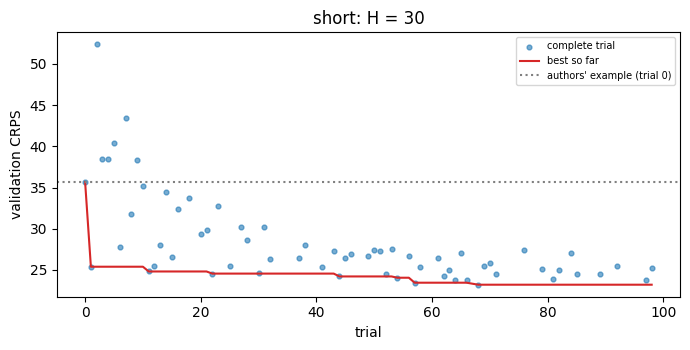

short: hyper-parameter importance (fANOVA, share of validation-CRPS variance explained)


,importance
lstm_hidden_dim,0.369
lr,0.211
lstm_num_layers,0.183
lstm_dropout,0.155
gcn_out_feat,0.074
noise_dist,0.008


In [11]:
rows = []
for hname, study in STUDIES.items():
    t0_ = next(t for t in study.trials if t.number == 0)
    bt = study.best_trial
    for label, t in [("authors' example (trial 0)", t0_), ("best", bt)]:
        rows.append({"horizon": hname, "H": SPLITS[hname]["H"], "trial": label, "number": t.number, "state": t.state.name,
                     "val CRPS": t.value, "sd over seeds": t.user_attrs.get("crps_sd_seeds"),
                     "val coverage95": t.user_attrs.get("coverage95"), "val width95": t.user_attrs.get("width95"),
                     **params_from_trial(t)})
tuning_summary = pd.DataFrame(rows).set_index(["horizon", "trial"])
print(f"Validation results: authors' example vs. best Optuna trial (CRPS in {CFG['UNITS']}, lower is better)")
display(tuning_summary.round(4))

fig, axes = plt.subplots(1, len(STUDIES), figsize=(7 * len(STUDIES), 3.6), squeeze=False)
for ax, (hname, study) in zip(axes[0], STUDIES.items()):
    done = [t for t in study.trials if t.state == TrialState.COMPLETE]
    x = [t.number for t in done]; y = [t.value for t in done]
    ax.scatter(x, y, s=12, alpha=0.6, label="complete trial")
    ax.plot(x, np.minimum.accumulate(y), color="tab:red", lw=1.5, label="best so far")
    t0v = next(t for t in study.trials if t.number == 0).value
    if t0v is not None:
        ax.axhline(t0v, color="gray", ls=":", label="authors' example (trial 0)")
    ax.set_title(f"{hname}: H = {SPLITS[hname]['H']}"); ax.set_xlabel("trial"); ax.set_ylabel("validation CRPS")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_optuna_history.png", dpi=150); plt.show()

for hname, study in STUDIES.items():
    try:
        imp = optuna.importance.get_param_importances(study)
        print(f"{hname}: hyper-parameter importance (fANOVA, share of validation-CRPS variance explained)")
        display(pd.Series(imp).round(3).to_frame("importance"))
    except Exception as e:                                # needs enough complete trials
        print(f"{hname}: importances not available ({e.__class__.__name__}: {e})")

## Part 8 — Save the study and best settings

In [12]:
out = CFG["OUT_DIR"]
tuning_summary.to_csv(f"{out}/tuning_summary_{HORIZON}.csv")
study.trials_dataframe().to_csv(f"{out}/optuna_trials_{HORIZON}.csv", index=False)
with open(f"{out}/best_params_{HORIZON}.json", "w") as fh:
    json.dump(dict(horizon=HORIZON, study_name=STUDY_NAME, best_value=study.best_value,
                   best_trial=study.best_trial.number, best_params=BEST[HORIZON], finished_trials=n_done,
                   fingerprint=tuning_fingerprint(HORIZON), versions=VERSIONS, device=str(DEVICE)),
              fh, indent=2, default=str)
os.replace(f"{out}/fig_optuna_history.png", f"{out}/fig_optuna_history_{HORIZON}.png")
print(sorted(os.listdir(out)))
print(f"\nNext: attach this notebook's output ({out}/optuna_{HORIZON}.db) to gcen-final.ipynb.")

['best_params_short.json', 'fig_optuna_history_short.png', 'optuna_short.db', 'optuna_trials_short.csv', 'tuning_summary_short.csv']

Next: attach this notebook's output (gcen_tuning_short/optuna_short.db) to gcen-final.ipynb.
